In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/Users/hanguyen/Documents/DATA ANALYTICS/IRONHACK/Week 5/amz_uk_price_prediction_dataset.csv')

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [18]:
category_frequency = df['category'].value_counts().reset_index()

In [28]:
category_frequency.dtypes

category    object
count        int64
dtype: object

In [35]:
top10 = category_frequency.head(10)

<Figure size 1000x600 with 0 Axes>

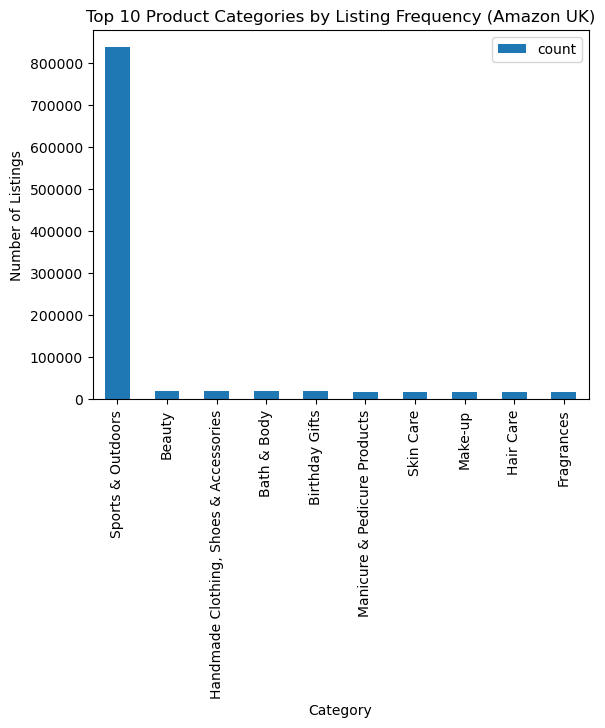

In [36]:
plt.figure(figsize=(10,6))
top10.plot(x='category', y='count', kind='bar')
plt.xlabel('Category')
plt.ylabel('Number of Listings')
plt.title('Top 10 Product Categories by Listing Frequency (Amazon UK)')
plt.show()

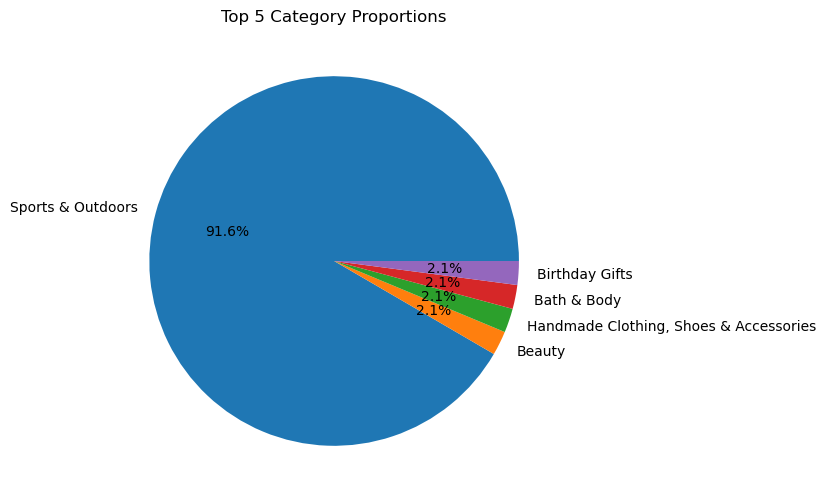

In [31]:
top5 = category_frequency.head(5)

plt.figure(figsize=(6,6))

plt.pie(top5['count'],
        labels=top5['category'],   # 👈 category names here
        autopct='%1.1f%%')

plt.title('Top 5 Category Proportions')
plt.show()


In [40]:
df.describe().round(2)

,uid,stars,reviews,price,boughtInLastMonth
count,2443651.00,2443651.00,2443651.00,2443651.00,2443651.00
mean,1370545.35,2.15,480.63,89.24,25.90
std,816056.17,2.19,5944.12,345.61,240.48
min,1.00,0.00,0.00,0.00,0.00
25%,658921.50,0.00,0.00,9.99,0.00
50%,1349029.00,0.00,0.00,19.09,0.00
75%,2060685.50,4.40,59.00,45.99,0.00
max,2828593.00,5.00,1356658.00,100000.00,50000.00


In [45]:
df['price'].mode()

0    9.99
Name: price, dtype: float64

In [ ]:
#Determine the variance, standard deviation, range, and interquartile range for product price.

df['price'].var()


In [53]:
print(f"The range of products prices is from ${df['price'].min()} to ${df['price'].max()}")

The range of products prices is from $0.0 to $100000.0


In [ ]:
# The most common price is 9.99, which is a common price point for many products on Amazon. This could indicate that many sellers are pricing their products at this level, compared to mean 89, std 149, median 19.99, which suggests a right-skewed distribution with some higher-priced outliers.

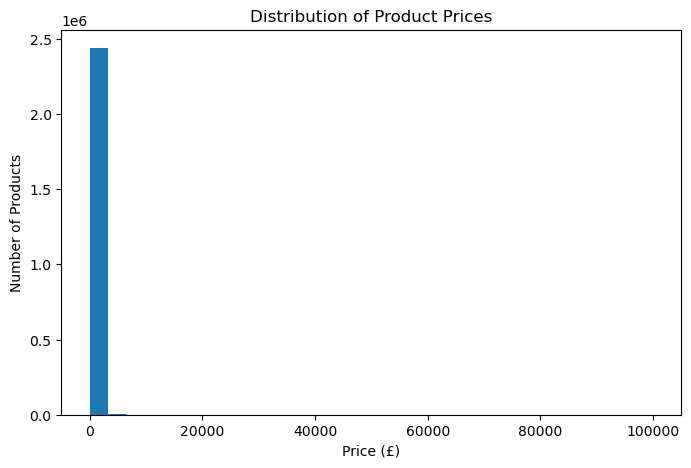

In [58]:
plt.figure(figsize=(8,5))

plt.hist(df['price'], bins=30)

plt.xlabel('Price (£)')
plt.ylabel('Number of Products')
plt.title('Distribution of Product Prices')

plt.show()

In [ ]:
#The histogram shows a strongly right-skewed distribution. Most products are priced at the lower end of the market (below £50), while a small number of high-priced items create a long tail. This explains why the standard deviation is much larger than the mean.

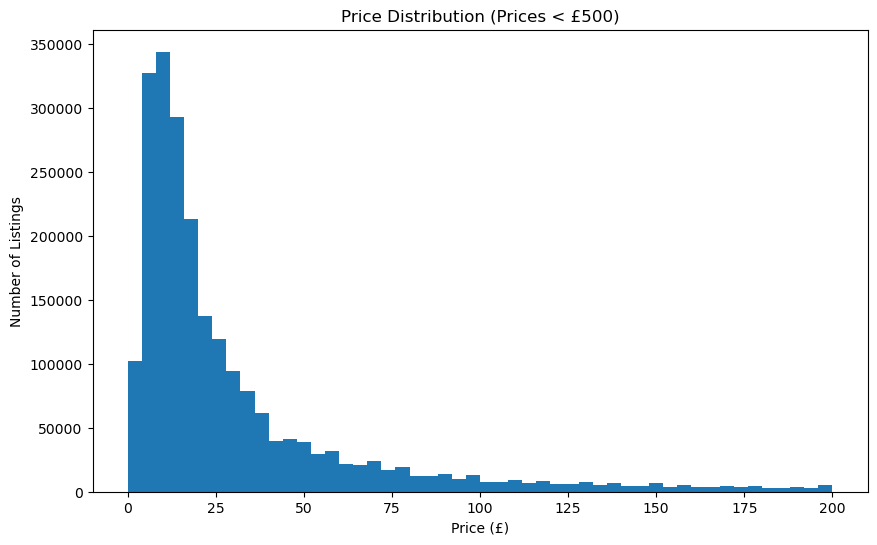

In [ ]:
#Solution: outliers can be removed to better visualize the distribution of the majority of products.

plt.figure(figsize=(10,6))

plt.hist(df[df['price'] < 200]['price'], bins=50)

plt.xlabel('Price (£)')
plt.ylabel('Number of Listings')
plt.title('Price Distribution (Prices < £500)')

plt.show()


In [ ]:
#Part 3: Unpacking Product Ratings

In [ ]:
#Calculate the mean, median, and mode for the rating of products.
print(f"Mean rating: {df['stars'].mean()}")
print(f"Median rating: {df['stars'].median()}")
print(f"Mode rating: {df['stars'].mode()}")

#The mode of product rating is 0, indicating that many products have no reviews at all. 
#The mean rating is 2.15, which is realiavely low, indicates that many products have low ratings.

Mean rating: 2.152836472966065
Median rating: 0.0
Mode rating: 0    0.0
Name: stars, dtype: float64


1356658

In [ ]:
#Determine the variance, standard deviation, and interquartile range for product rating.
print(f"Variance: {df['stars'].var()}")
print(f"Standard Deviation: {df['stars'].std()}")
print(f"Interquartile Range: {df['stars'].quantile(0.75) - df['stars'].quantile(0.25)}")

# the standard deviation o 2.19 indicates that ratings are spread out around the mean of 2.15. 
# The interquartile range of 2 shows that the middle 50% of ratings fall within a 4.4-point range
# There is wide variation in product ratings. 

Variance: 4.81743402976196
Standard Deviation: 2.1948653785054697
Interquartile Range: 4.4


In [19]:
df['stars'].agg(['skew', 'kurt'])

skew    0.081207
kurt   -1.926006
Name: stars, dtype: float64

In [ ]:
# Ratings are almost evenly distributed around the mean.
# More evenly spread. No strong concentration at one score.

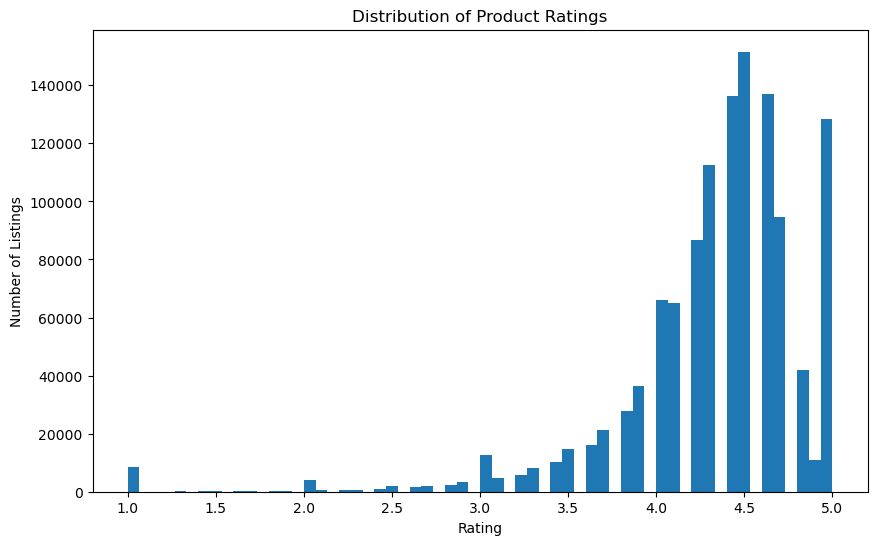

In [ ]:
#Histogram of product ratings (excluding 0 ratings to focus on products with reviews)
plt.figure(figsize=(10,6))

plt.hist(df[df['stars'] > 0]['stars'], bins=60)

plt.xlabel('Rating')
plt.ylabel('Number of Listings')
plt.title('Distribution of Product Ratings')

plt.show()


In [ ]:
#The most comon product rating is 4.5.